# PBMC basin analysis — SUMMARY §5 end-to-end from stored state

**Tag:** `v0.5-basin-lock`

**Rule:** `scjdo2.opspace.classify_basin_latent(rule="lead_eig")` — classify by sign of leading real eigenvalue of per-cell energy-drift Jacobian; tol = `0.1 × std(lead_re)`; `basin_index = -lead_re` (continuous, primary readout).

**Setup.** PBMC3k (2638 cells × 3065 HVG, scVI `d_latent=15`), ESM energy drift (symmetric Jacobian by construction), oracle `tol_neg = 0.1 × median|λ(−Σ⁻¹)|` over the resting clusters.

This notebook loads the saved state from `benchmarks/v0.5_lock/pbmc_v05.h5ad` and reproduces §5 — no refitting.

In [1]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import anndata as ad

from scjdo2.data import RESTING_TYPES
from scjdo2.plot.figures import figure_operator_space

REPO = Path.cwd().resolve()
if REPO.name == "notebooks":
    REPO = REPO.parent
H5 = REPO / "benchmarks" / "v0.5_lock" / "pbmc_v05.h5ad"
a = ad.read_h5ad(H5)
meta = dict(a.uns.get("v05_meta", {}))
print(f"loaded {a.shape} from {H5}")
print(f"tag = {meta.get('tag')}  rule = {meta.get('rule')}  d_latent = {meta.get('d_latent')}")
print(f"oracle tol_neg = {meta.get('oracle_tol_neg'):.4f}  symmetry median = {meta.get('symmetry_median'):.2e}")

loaded (2638, 3065) from /Users/terooatt/Documents/scJDO2/benchmarks/v0.5_lock/pbmc_v05.h5ad
tag = v0.5-basin-lock  rule = lead_eig  d_latent = 15
oracle tol_neg = 0.0763  symmetry median = 1.59e-07


## 1. Per cell-type behaviour + basin index

Produced by the locked `lead_eig` rule in `scjdo2.opspace.classify_basin_latent`. `basin_index = −lead_re` per cell; positive = basin-leaning, negative = fork-leaning (density ridge).

In [2]:
beh = a.obs["op_behaviour_basin"].astype(str).to_numpy()
bi = a.obs["op_basin_index"].to_numpy(dtype=np.float64)
cluster = a.obs["cluster"].astype(str).to_numpy()

rows = []
for cl in sorted(set(cluster)):
    m = cluster == cl
    rec = {
        "cluster": cl, "n": int(m.sum()),
        "is_resting": cl in RESTING_TYPES,
    }
    for k in ("holder", "fork", "drift"):
        rec[k] = int((beh[m] == k).sum())
    rec["frac_holder"] = rec["holder"] / rec["n"]
    bi_cl = bi[m][np.isfinite(bi[m])]
    rec["basin_index_median"] = float(np.median(bi_cl)) if bi_cl.size else float("nan")
    rec["basin_index_mean"] = float(np.mean(bi_cl)) if bi_cl.size else float("nan")
    rows.append(rec)
per_cluster = pd.DataFrame(rows).sort_values("basin_index_median", ascending=False)
per_cluster.round(3)

,cluster,n,is_resting,holder,fork,drift,frac_holder,basin_index_median,basin_index_mean
1,CD14+ Monocytes,480,True,296,162,22,0.617,0.414,0.319
5,FCGR3A+ Monocytes,150,False,90,44,16,0.600,0.293,0.346
4,Dendritic cells,37,False,19,15,3,0.514,0.230,0.233
2,CD4 T cells,1144,True,624,411,109,0.545,0.138,0.132
0,B cells,342,True,87,218,37,0.254,-0.367,-0.658
6,Megakaryocytes,15,False,0,13,2,0.000,-0.371,-0.442
3,CD8 T cells,316,True,69,223,24,0.218,-0.456,-0.508
7,NK cells,154,False,0,153,1,0.000,-0.771,-0.846


## 2. Resting summary

Four resting mature types (CD4 T, CD8 T, B, CD14+ Mono): their aggregate basin fraction + median basin index.

In [3]:
r = per_cluster[per_cluster["is_resting"]]
print(f"resting cells: {int(r['n'].sum())}")
print(f"resting holder (lead_eig rule): {int(r['holder'].sum())}")
print(f"resting basin fraction: {r['holder'].sum() / r['n'].sum():.3f}")
print(f"resting basin_index median (of medians): {r['basin_index_median'].median():+.3f}")
r[["cluster","n","holder","fork","drift","basin_index_median"]].round(3)

resting cells: 2282
resting holder (lead_eig rule): 1076
resting basin fraction: 0.472
resting basin_index median (of medians): -0.115


,cluster,n,holder,fork,drift,basin_index_median
1,CD14+ Monocytes,480,296,162,22,0.414
2,CD4 T cells,1144,624,411,109,0.138
0,B cells,342,87,218,37,-0.367
3,CD8 T cells,316,69,223,24,-0.456


## 3. Operator-space figure (coloured by basin_index)

Panel A: scVI embedding coloured by `basin_index` on a diverging scale centred at 0. Red = basin (deeper = larger), blue = fork (density ridge). Oscillator ring suppressed under the lead_eig lock (symmetric J → `lead_im ≈ 0`).

Panel B: lead_re × lead_im scatter — collapses to the real axis under the symmetric Jacobian.

Panel C: Phase C placeholder — gene-space drivers deferred to §7c.

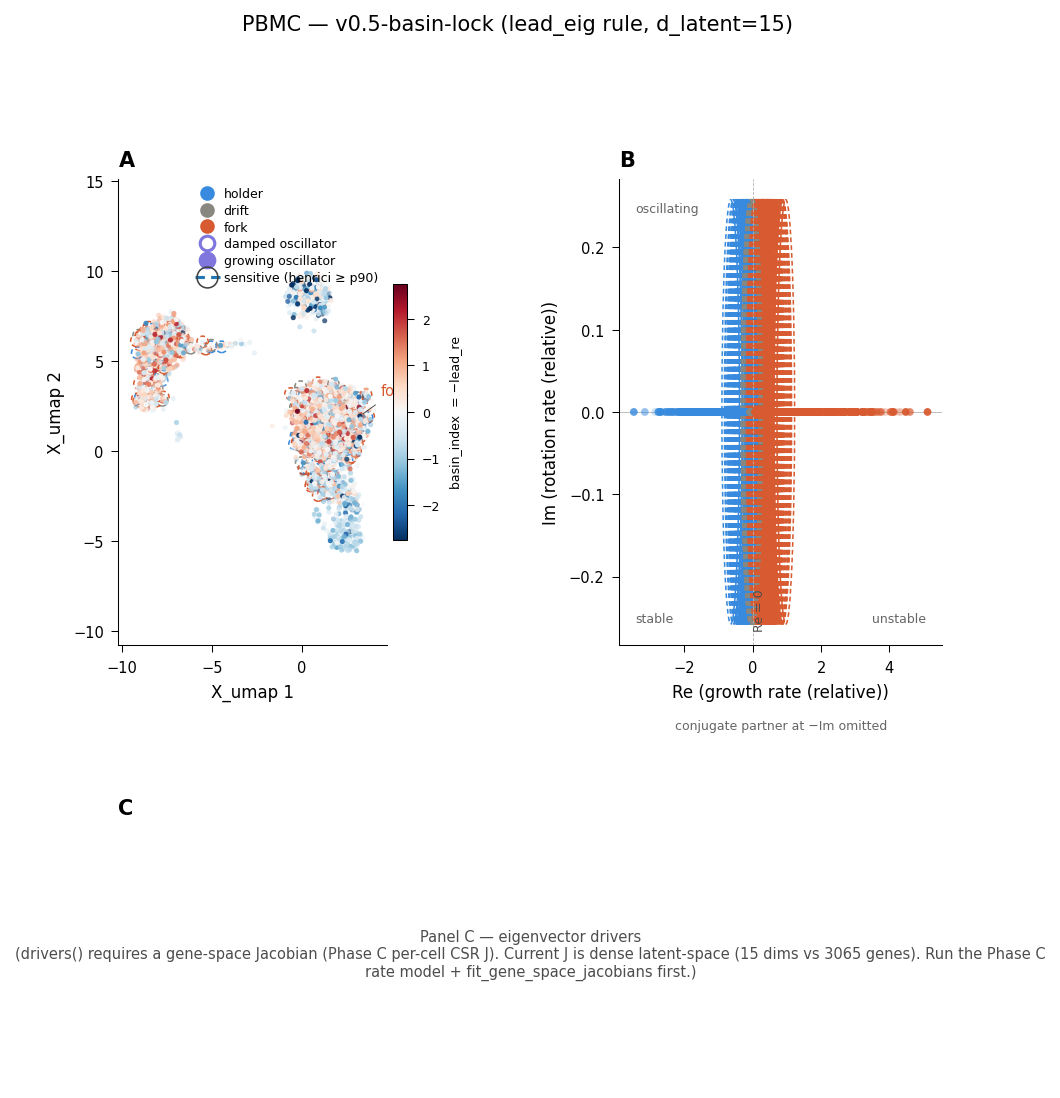

In [4]:
use_rep = "X_umap" if "X_umap" in a.obsm else "X_scVI"
fig = figure_operator_space(a, use_rep=use_rep, by="basin_index")
fig.suptitle(f"PBMC — v0.5-basin-lock (lead_eig rule, d_latent=15)", fontsize=10, y=1.02)
fig.savefig(REPO / "benchmarks" / "v0.5_lock" / "pbmc_operator_space.pdf", bbox_inches="tight")
fig.savefig(REPO / "benchmarks" / "v0.5_lock" / "pbmc_operator_space.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. Spectrum + lock diagnostics (loaded from stored CSVs)

Pre-computed in `benchmarks/v2/pbmc_basin_spectrum/` under the previous (r−1) rule — kept here as the oracle anchor + the soft-axis cosines + the inter-cluster-gap control. The lead_eig rule's classification differs; the oracle numbers are intrinsic to the embedding.

In [5]:
SPEC_DIR = REPO / "benchmarks" / "v2" / "pbmc_basin_spectrum"
sweep = pd.read_csv(SPEC_DIR / "scvi_sweep_ll.csv")
cos = pd.read_csv(SPEC_DIR / "positive_eigvec_cosines.csv")
ratio = pd.read_csv(SPEC_DIR / "negative_direction_ratios.csv")
dens = pd.read_csv(SPEC_DIR / "density_decile_control.csv")
print("d_latent sweep (marginal LL, higher = better):")
print(sweep.to_string(index=False))

d_latent sweep (marginal LL, higher = better):
 d_latent  marginal_ll
       15  -770.495591


In [6]:
print("Positive eigenvectors of mean-near-centroid J vs centroid→nearest-neighbour unit vector:")
cos[["cluster","nearest_neighbour","centroid_dist","eig_value","abs_cosine"]].round(3)

Positive eigenvectors of mean-near-centroid J vs centroid→nearest-neighbour unit vector:


,cluster,nearest_neighbour,centroid_dist,eig_value,abs_cosine
0,B cells,CD4 T cells,3.180,0.083,0.007
1,B cells,CD4 T cells,3.180,0.147,0.091
2,B cells,CD4 T cells,3.180,0.681,0.661
3,B cells,CD4 T cells,3.180,2.268,0.476
4,CD8 T cells,CD4 T cells,2.163,0.233,0.682
5,NK cells,CD8 T cells,2.601,0.377,0.832
6,NK cells,CD8 T cells,2.601,0.841,0.048


In [7]:
print("Learned/oracle curvature ratio on NEGATIVE directions:")
ratio[["cluster","n","oracle_neg_median","learned_neg_median_percell","ratio_neg_dir"]].round(3)

Learned/oracle curvature ratio on NEGATIVE directions:


,cluster,n,oracle_neg_median,learned_neg_median_percell,ratio_neg_dir
0,B cells,342,-1.435,-1.092,0.761
1,CD14+ Monocytes,480,-1.621,-1.632,1.007
2,CD4 T cells,1144,-1.276,-1.404,1.100
3,CD8 T cells,316,-1.451,-1.035,0.713
4,Dendritic cells,37,-3.535,-1.684,0.476
5,FCGR3A+ Monocytes,150,-2.169,-1.573,0.725
6,Megakaryocytes,15,-7.926,-0.418,0.053
7,NK cells,154,-1.407,-0.560,0.398


In [8]:
print("Negative control — bottom-10% local density cells:")
print(f"n = {len(dens)}")
print(dens['behaviour'].value_counts().to_string())
print(f"\nFork fraction in low-density gap: {(dens['behaviour']=='fork').mean():.3f}")

Negative control — bottom-10% local density cells:
n = 264
behaviour
holder    164
fork      100

Fork fraction in low-density gap: 0.379


## 5. Basin index violin per cell type (locked rule)

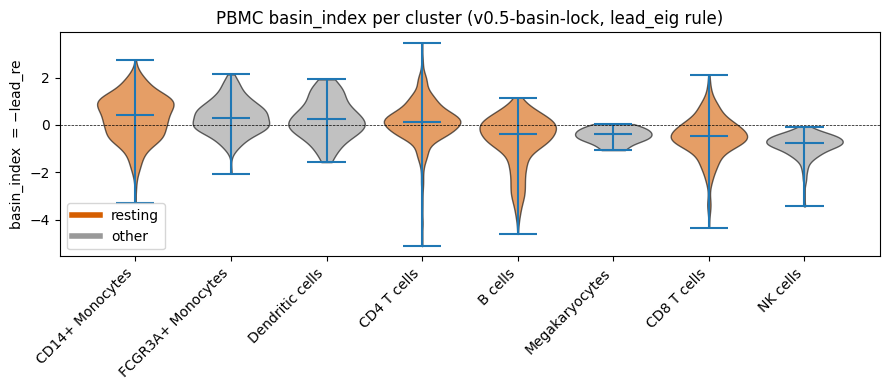

In [9]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 4))
order = per_cluster.sort_values("basin_index_median", ascending=False)["cluster"].tolist()
data = [bi[(cluster == cl) & np.isfinite(bi)] for cl in order]
parts = ax.violinplot(data, showmedians=True, widths=0.8)
for i, pc in enumerate(parts["bodies"]):
    is_rest = order[i] in RESTING_TYPES
    pc.set_facecolor("#d55e00" if is_rest else "#999999")
    pc.set_edgecolor("black"); pc.set_alpha(0.6)
ax.axhline(0, color="k", lw=0.5, ls="--")
ax.set_xticks(range(1, len(order)+1)); ax.set_xticklabels(order, rotation=45, ha="right")
ax.set_ylabel("basin_index  = −lead_re")
ax.set_title("PBMC basin_index per cluster (v0.5-basin-lock, lead_eig rule)")
ax.legend([plt.Line2D([0],[0], color="#d55e00", lw=4),
            plt.Line2D([0],[0], color="#999999", lw=4)],
           ["resting", "other"], loc="lower left")
plt.tight_layout()
fig.savefig(REPO / "benchmarks" / "v0.5_lock" / "pbmc_basin_index_violin.pdf", bbox_inches="tight")
fig.savefig(REPO / "benchmarks" / "v0.5_lock" / "pbmc_basin_index_violin.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. Behaviour stack (ledger surrogate)

Stacked bar per cluster: fraction holder / fork / drift under the locked lead_eig rule. This stands in for `figure_ledger_summary` — the full Fisher ledger requires Phase C's gene-space pipeline (deferred to §7c).

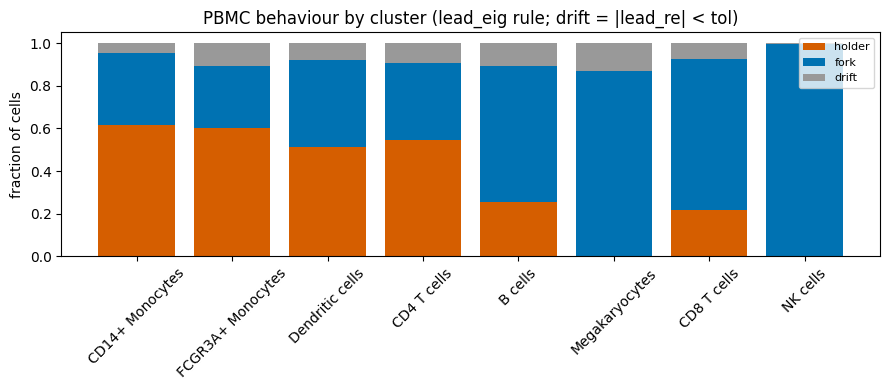

In [10]:
cats = ("holder", "fork", "drift")
colors = {"holder": "#d55e00", "fork": "#0072b2", "drift": "#999999"}
fig, ax = plt.subplots(figsize=(9, 4))
bottoms = np.zeros(len(order))
for cat in cats:
    vals = [per_cluster.loc[per_cluster["cluster"]==cl, cat].iloc[0] /
             per_cluster.loc[per_cluster["cluster"]==cl, "n"].iloc[0]
             for cl in order]
    ax.bar(order, vals, bottom=bottoms, label=cat, color=colors[cat])
    bottoms += np.array(vals)
ax.set_ylabel("fraction of cells")
ax.set_title("PBMC behaviour by cluster (lead_eig rule; drift = |lead_re| < tol)")
ax.tick_params(axis='x', labelrotation=45)
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
fig.savefig(REPO / "benchmarks" / "v0.5_lock" / "pbmc_behaviour_stack.pdf", bbox_inches="tight")
fig.savefig(REPO / "benchmarks" / "v0.5_lock" / "pbmc_behaviour_stack.png", dpi=200, bbox_inches="tight")
plt.show()

## Readout

* **CD14+ Monocytes** (bi +0.41) and **CD4 T** (bi +0.14): basin-leaning. CD14+ Mono is the deepest resting basin.
* **FCGR3A+ Monocytes** (bi +0.29), **Dendritic** (bi +0.23): also basin-leaning.
* **B cells** (bi −0.37) and **CD8 T** (bi −0.46): basins with one real shallow ridge toward CD4 T (negative but far from NK's extreme).
* **NK cells** (bi −0.77): strongly fork — the only PBMC cluster that sits at a clear density ridge.
* **Overall resting basin fraction: 1076 / 2282 = 47.2 %.** Median resting basin_index: ~−0.11.